# Controller Comparison

This notebook compares the nine demos from the data each one saves in `results/simulation_data.npz`. Run a demo's `main.py` to refresh its data, then rerun this notebook.

Read the comparison with the setups in mind:

- **Demos 1–3** control from the true state with an exact model. Demo 1 regulates only attitude and elevation; demos 2 and 3 fly the same figure-8 as demos 4–9.
- **Demos 4–9** measure only noisy position and Euler angles (1 mm and 0.1° standard deviation), use a model whose mass and inertia are 6–9% off, and start with the same estimation errors. Their numbers are directly comparable.
- The MPC demos 5 and 6 update their input every 50 ms; all other controllers every 10 ms.

In [1]:
import glob
import os

import numpy as np
import matplotlib.pyplot as plt

# Light chart surface, text inks and the first two categorical slots of the reference palette
Surface = "#fcfcfb"
TextPrimary = "#0b0b0b"
TextSecondary = "#52514e"
GridColor = "#e4e3df"
TrueStateColor = "#2a78d6"
ObserverColor = "#eb6834"
ReferenceColor = "#8a8984"

plt.rcParams.update({
    "figure.facecolor": Surface, "axes.facecolor": Surface, "savefig.facecolor": Surface,
    "axes.edgecolor": GridColor, "axes.labelcolor": TextSecondary, "axes.titlecolor": TextPrimary,
    "xtick.color": TextSecondary, "ytick.color": TextSecondary, "text.color": TextPrimary,
    "axes.grid": True, "grid.color": GridColor, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "lines.linewidth": 2.0,
})

Demos = {}
for Path in sorted(glob.glob(os.path.join("*", "results", "simulation_data.npz"))):
    Data = np.load(Path)
    Name = str(Data["Name"])
    Demos[Name] = {Key: Data[Key] for Key in Data.files if Key != "Name"}

for Name, D in Demos.items():
    Kind = "noisy sensors + observer" if "Estimate" in D else "true state"
    print(f"{Name:55s} {len(D['Time']):5d} samples, dt = {D['Time'][1] - D['Time'][0]:.2f} s, {Kind}")

1. Attitude + Elevation Controller                       1001 samples, dt = 0.01 s, true state
2. Yaw Angle + Position Controller                       1001 samples, dt = 0.01 s, true state
3. Output Feedback Control with Feedback Linearization   1001 samples, dt = 0.01 s, true state
4. Sliding-Mode Controller + Observer                    1001 samples, dt = 0.01 s, noisy sensors + observer
5. EKF + MPC                                              201 samples, dt = 0.05 s, noisy sensors + observer
6. EKF + NN-Adaptive MPC                                  201 samples, dt = 0.05 s, noisy sensors + observer
7. EKF + LQR                                             1001 samples, dt = 0.01 s, noisy sensors + observer
8. EKF + Backstepping                                    1001 samples, dt = 0.01 s, noisy sensors + observer
9. EKF + Geometric Control                               1001 samples, dt = 0.01 s, noisy sensors + observer


## Metrics

All metrics cover the whole 10 s run, except "after 3 s", the position RMSE once the start-up transient is over. Chattering is the total variation of the input per second, which is comparable across control rates. Estimation errors are measured from t ≥ 1 s, after the initial estimate errors have converged.

In [2]:
Labels = {
    "1": "1  Attitude + Elevation", "2": "2  Yaw + Position", "3": "3  Feedback Linearization",
    "4": "4  Sliding-Mode + SMO", "5": "5  EKF + MPC", "6": "6  EKF + NN-Adaptive MPC",
    "7": "7  EKF + LQR", "8": "8  EKF + Backstepping", "9": "9  EKF + Geometric Control",
}


def Short(Name):
    return Labels[Name.split(".", 1)[0]]


def Metrics(D):
    Time, Motion, Reference, Control = D["Time"], D["Motion"], D["Reference"], D["Control"]
    Error = Motion[:, 0:3] - Reference[:, 0:3]
    Duration = Time[-1] - Time[0]
    M = {
        "PositionRMSE": np.sqrt(np.mean(np.sum(Error ** 2, axis=1))),
        "AxisRMSE": np.sqrt(np.mean(Error ** 2, axis=0)),
        "MaxError": np.max(np.linalg.norm(Error, axis=1)),
        "MaxZError": np.max(np.abs(Error[:, 2])),
        "SteadyRMSE": np.sqrt(np.mean(np.sum(Error[Time >= 3.0] ** 2, axis=1))),
        "SteadyZRMSE": np.sqrt(np.mean(Error[Time >= 3.0, 2] ** 2)),
        "YawRMSE": np.sqrt(np.mean((Motion[:, 8] - Reference[:, 8]) ** 2)),
        "MaxTilt": np.rad2deg(np.max(np.abs(Motion[:, 6:8]))),
        "ThrustVariation": np.sum(np.abs(np.diff(Control[:, 0]))) / Duration,
        "TorqueVariation": np.sum(np.linalg.norm(np.diff(Control[:, 1:4], axis=0), axis=1)) / Duration * 1e3,
    }
    if "Estimate" in D:
        Settled = Time >= 1.0
        EstimateError = D["Estimate"][Settled] - Motion[Settled]
        M["VelocityEstimate"] = np.sqrt(np.mean(EstimateError[:, 3:6] ** 2))
        M["RateEstimate"] = np.sqrt(np.mean(EstimateError[:, 9:12] ** 2))
    return M


Results = {Name: Metrics(D) for Name, D in Demos.items()}

Header = (f"{'Demo':27s} {'pos RMSE':>11s} {'after 3 s':>10s} {'max err':>9s} {'yaw RMSE':>9s} {'max tilt':>9s} "
          f"{'dT/s':>6s} {'dTau/s':>7s} {'v est':>7s} {'w est':>7s}")
print(Header)
print("-" * len(Header))
for Name, M in Results.items():
    ElevationOnly = Name.startswith("1.")
    Position = f"{M['AxisRMSE'][2]:.3f} m (z)" if ElevationOnly else f"{M['PositionRMSE']:.3f} m"
    MaxError = f"{M['MaxZError'] if ElevationOnly else M['MaxError']:.3f} m"
    Steady = f"{M['SteadyZRMSE'] if ElevationOnly else M['SteadyRMSE']:.4f} m"
    Estimates = (f"{M['VelocityEstimate']:7.4f} {M['RateEstimate']:7.4f}" if "VelocityEstimate" in M
                 else f"{'-':>7s} {'-':>7s}")
    print(f"{Short(Name):27s} {Position:>11s} {Steady:>10s} {MaxError:>9s} {M['YawRMSE']:5.3f} rad "
          f"{M['MaxTilt']:5.1f} deg {M['ThrustVariation']:6.2f} {M['TorqueVariation']:7.1f} {Estimates}")
print()
print("dT/s in N/s, dTau/s in 1e-3 N m/s, v est in m/s, w est in rad/s.")
print("Demo 1 tracks elevation only, so its position errors are for z alone.")

Demo                           pos RMSE  after 3 s   max err  yaw RMSE  max tilt   dT/s  dTau/s   v est   w est
---------------------------------------------------------------------------------------------------------------
1  Attitude + Elevation     0.046 m (z)   0.0001 m   0.200 m 0.014 rad   3.4 deg   0.07     1.9       -       -
2  Yaw + Position               0.019 m   0.0208 m   0.039 m 0.022 rad  20.0 deg   0.53    21.3       -       -
3  Feedback Linearization       0.024 m   0.0004 m   0.088 m 0.009 rad  19.5 deg   0.52    10.0       -       -
4  Sliding-Mode + SMO           0.032 m   0.0280 m   0.089 m 0.011 rad  22.8 deg   2.47   197.1  0.0150  0.0109
5  EKF + MPC                    0.026 m   0.0282 m   0.045 m 0.019 rad  19.0 deg   1.02   100.0  0.0109  0.0122
6  EKF + NN-Adaptive MPC        0.040 m   0.0343 m   0.071 m 0.019 rad  19.0 deg   1.10    83.3  0.0166  0.0123
7  EKF + LQR                    0.013 m   0.0096 m   0.041 m 0.013 rad  19.8 deg   3.42   223.3  0.0176 

## Tracking Accuracy

Position and yaw RMSE side by side, one chart per measure. Blue bars control from the true state; orange bars measure only noisy position and attitude and run an observer with a wrong model. Demo 1 has no position bar because it does not regulate horizontal position.

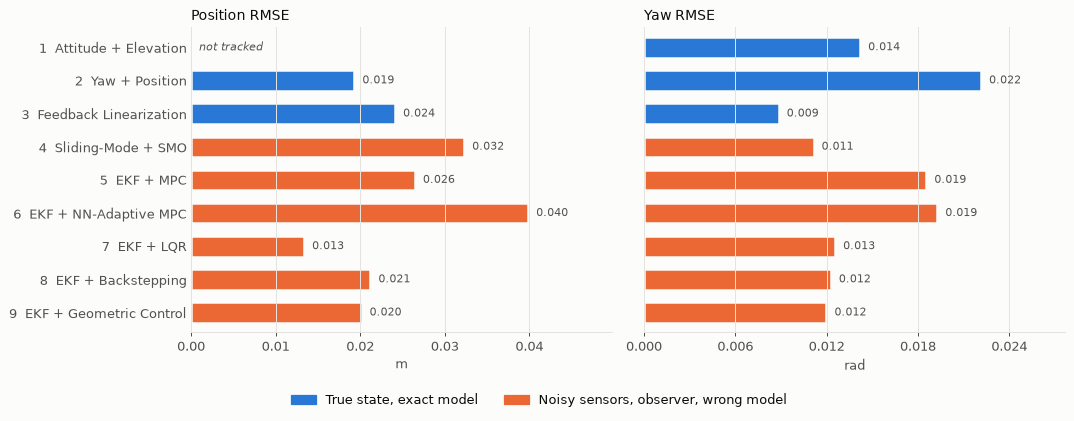

In [3]:
def GroupColor(Name):
    return ObserverColor if "Estimate" in Demos[Name] else TrueStateColor


def BarChart(Ax, Names, Values, Title, Unit, Digits=3, ShowLabels=True):
    # Values may contain None for a demo the measure does not apply to
    Positions = np.arange(len(Names))[::-1]
    Largest = max(V for V in Values if V is not None)
    for Y, Name, V in zip(Positions, Names, Values):
        if V is None:
            Ax.text(0, Y, "  not tracked", va="center", ha="left", color=TextSecondary, fontsize=9, style="italic")
            continue
        Ax.barh(Y, V, height=0.62, color=GroupColor(Name), edgecolor=Surface, linewidth=2)
        Ax.text(V, Y, f"  {V:.{Digits}f}", va="center", ha="left", color=TextSecondary, fontsize=9)
    Ax.set_yticks(Positions, [Short(N) for N in Names] if ShowLabels else [])
    Ax.tick_params(axis="y", length=0)
    Ax.xaxis.set_major_locator(plt.MaxNLocator(5))
    Ax.set_xlim(0, Largest * 1.25)
    Ax.set_ylim(-0.6, len(Names) - 0.4)
    Ax.set_title(Title, loc="left")
    Ax.set_xlabel(Unit)
    Ax.grid(axis="y", visible=False)


def GroupLegend(Fig):
    Handles = [plt.Rectangle((0, 0), 1, 1, color=TrueStateColor), plt.Rectangle((0, 0), 1, 1, color=ObserverColor)]
    Fig.legend(Handles, ["True state, exact model", "Noisy sensors, observer, wrong model"],
               loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))


Names = list(Results)
Fig, Axes = plt.subplots(1, 2, figsize=(12, 4.6))
BarChart(Axes[0], Names, [None if N.startswith("1.") else Results[N]["PositionRMSE"] for N in Names], "Position RMSE", "m")
BarChart(Axes[1], Names, [Results[N]["YawRMSE"] for N in Names], "Yaw RMSE", "rad", ShowLabels=False)
GroupLegend(Fig)
Fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## Tracking Error over Time

The position error norm of the eight demos that fly the figure-8, one panel each on a shared scale. The observer-based demos all start from the same wrong estimate, so their first second shows how each design recovers.

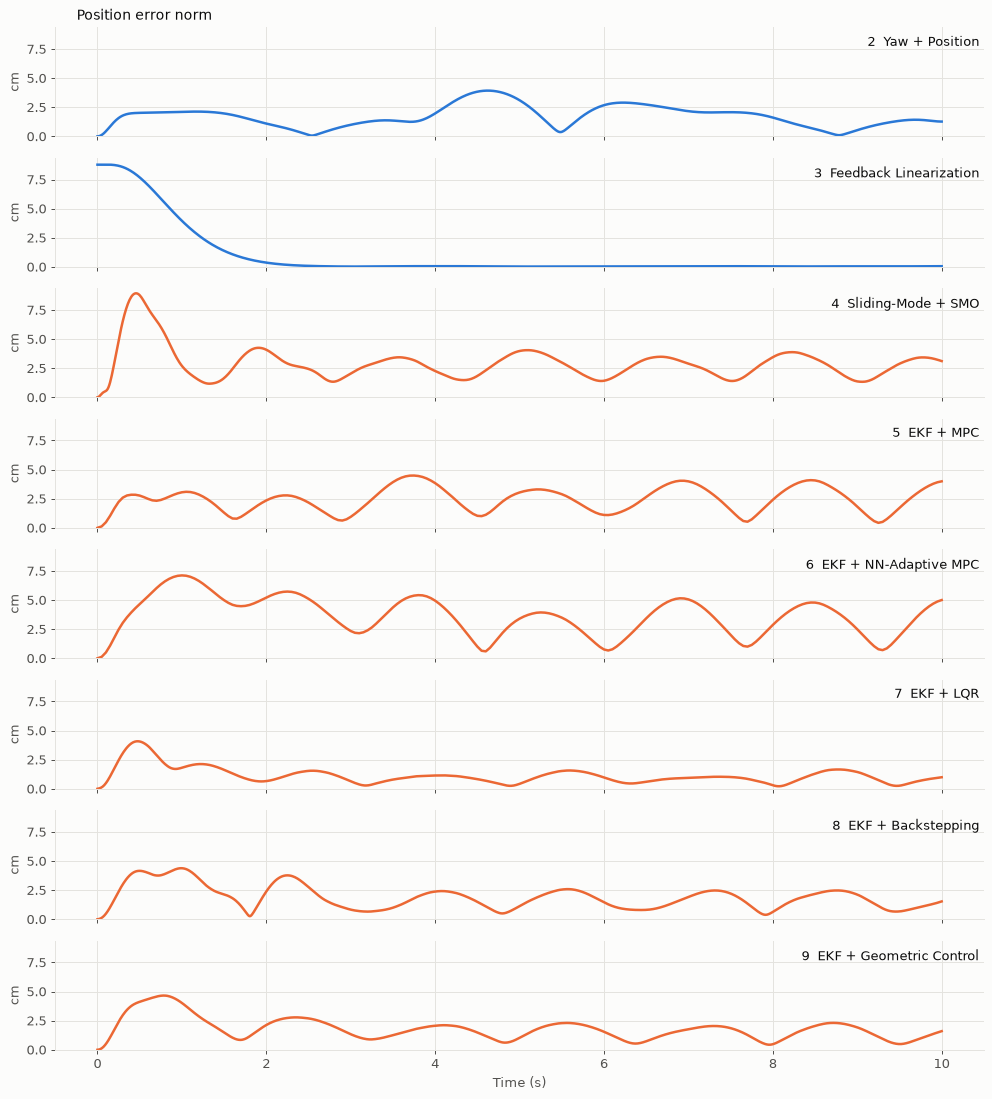

In [4]:
SameTrajectory = [N for N in Names if not N.startswith("1.")]
Fig, Axes = plt.subplots(len(SameTrajectory), 1, figsize=(11, 1.55 * len(SameTrajectory)), sharex=True, sharey=True)
for Ax, Name in zip(Axes, SameTrajectory):
    D = Demos[Name]
    ErrorNorm = np.linalg.norm(D["Motion"][:, 0:3] - D["Reference"][:, 0:3], axis=1) * 100
    Ax.plot(D["Time"], ErrorNorm, color=GroupColor(Name))
    Ax.text(0.995, 0.92, Short(Name), transform=Ax.transAxes, ha="right", va="top", color=TextPrimary, fontsize=10)
    Ax.set_ylabel("cm")
Axes[0].set_ylim(0, None)
Axes[-1].set_xlabel("Time (s)")
Fig.suptitle("Position error norm", x=0.07, ha="left", fontsize=11)
Fig.tight_layout()
plt.show()

## Flight Paths

Top view of each flight against its reference (gray, dashed). Demo 1 has no horizontal reference, so it drifts.

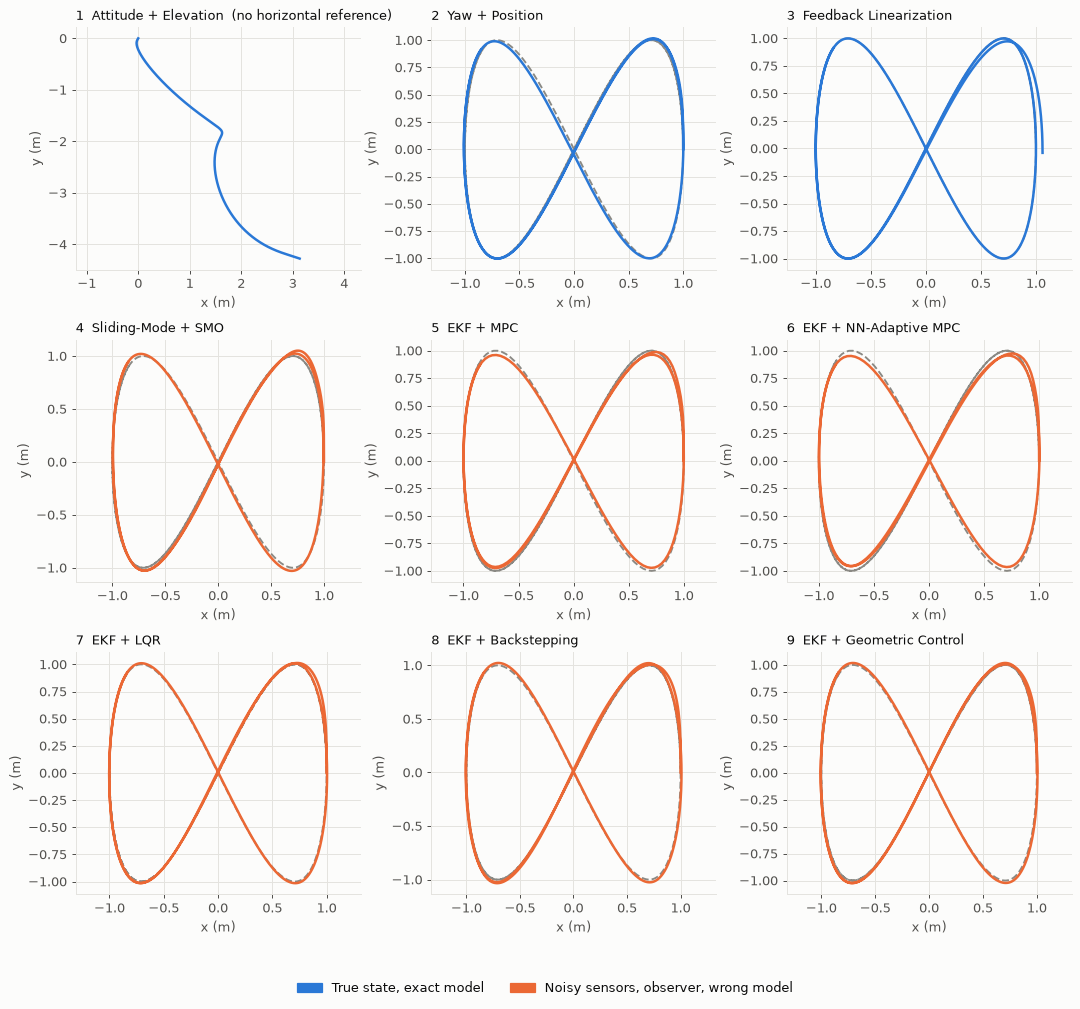

In [5]:
Fig, Axes = plt.subplots(3, 3, figsize=(12, 11))
for Ax, Name in zip(Axes.flat, Names):
    D = Demos[Name]
    Ax.plot(D["Reference"][:, 0], D["Reference"][:, 1], "--", color=ReferenceColor, linewidth=1.5)
    Ax.plot(D["Motion"][:, 0], D["Motion"][:, 1], color=GroupColor(Name))
    Ax.set_title(Short(Name) + ("  (no horizontal reference)" if Name.startswith("1.") else ""), loc="left", fontsize=10)
    Ax.set_aspect("equal", adjustable="datalim")
    Ax.set_xlabel("x (m)")
    Ax.set_ylabel("y (m)")
GroupLegend(Fig)
Fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

## Control Effort

How much the inputs move. Lower is smoother and easier on the motors. The observer-based demos feed sensor noise through their estimates, so they chatter more than the true-state demos.

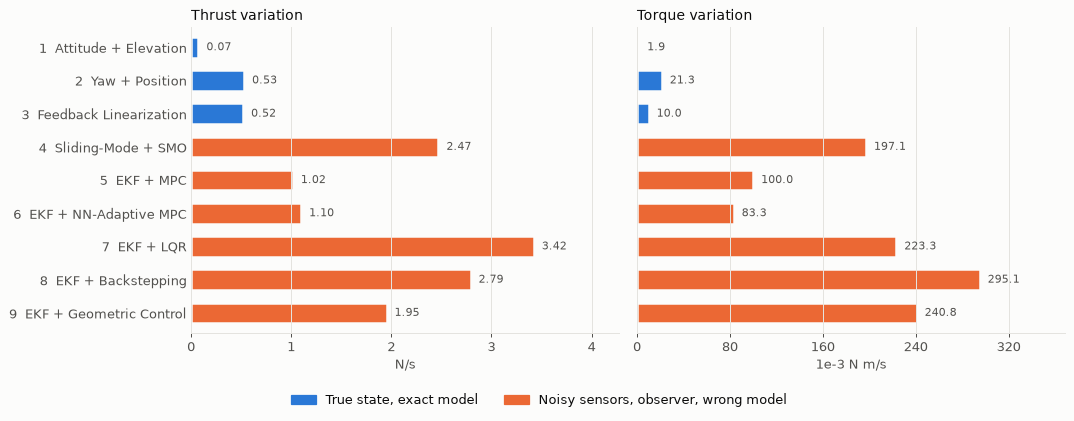

In [6]:
Fig, Axes = plt.subplots(1, 2, figsize=(12, 4.6))
BarChart(Axes[0], Names, [Results[N]["ThrustVariation"] for N in Names], "Thrust variation", "N/s", Digits=2)
BarChart(Axes[1], Names, [Results[N]["TorqueVariation"] for N in Names], "Torque variation", "1e-3 N m/s", Digits=1, ShowLabels=False)
GroupLegend(Fig)
Fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## State Estimation

Estimation accuracy of the six observer-based demos after the first second. Demo 4 uses a sliding-mode observer; demos 5–9 use an extended Kalman filter. The EKF in demo 5 also estimates a constant acceleration disturbance, and the one in demo 6 predicts with a learned model.

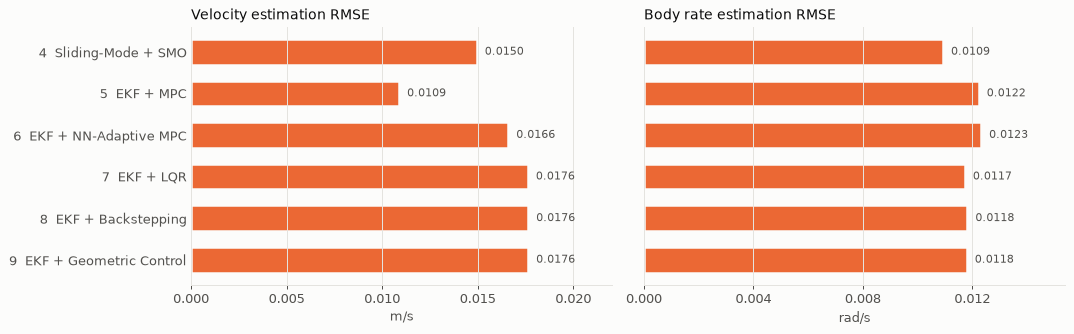

In [7]:
ObserverNames = [N for N in Names if "Estimate" in Demos[N]]
Fig, Axes = plt.subplots(1, 2, figsize=(12, 3.8))
BarChart(Axes[0], ObserverNames, [Results[N]["VelocityEstimate"] for N in ObserverNames], "Velocity estimation RMSE", "m/s", Digits=4)
BarChart(Axes[1], ObserverNames, [Results[N]["RateEstimate"] for N in ObserverNames], "Body rate estimation RMSE", "rad/s", Digits=4, ShowLabels=False)
Fig.tight_layout()
plt.show()

## Ranking of the Observer-Based Designs

Demos 4–9 share sensors, model error, initial errors and trajectory, so this is the fair ranking.

In [8]:
Ranked = sorted(ObserverNames, key=lambda N: Results[N]["PositionRMSE"])
for Rank, Name in enumerate(Ranked, 1):
    M = Results[Name]
    print(f"{Rank}. {Short(Name):32s} position {M['PositionRMSE'] * 100:4.1f} cm, yaw {M['YawRMSE']:.3f} rad, "
          f"thrust variation {M['ThrustVariation']:.2f} N/s")

1. 7  EKF + LQR                     position  1.3 cm, yaw 0.013 rad, thrust variation 3.42 N/s
2. 9  EKF + Geometric Control       position  2.0 cm, yaw 0.012 rad, thrust variation 1.95 N/s
3. 8  EKF + Backstepping            position  2.1 cm, yaw 0.012 rad, thrust variation 2.79 N/s
4. 5  EKF + MPC                     position  2.6 cm, yaw 0.019 rad, thrust variation 1.02 N/s
5. 4  Sliding-Mode + SMO            position  3.2 cm, yaw 0.011 rad, thrust variation 2.47 N/s
6. 6  EKF + NN-Adaptive MPC         position  4.0 cm, yaw 0.019 rad, thrust variation 1.10 N/s


## Observations

- **Feedback linearization (demo 3) shows the ideal case.** With the true state and an exact model, its error after the first 3 s is under a millimetre, against 1.0–3.4 cm for the observer-based designs and 2.1 cm for the cascaded PID of demo 2, which has the same perfect information. The exact inversion and the perfect information both contribute to that gap. Its full-run RMSE is higher only because it starts 9 cm off the reference, while demos 4–9 start on the reference with a wrong estimate.
- **The time-varying LQR (demo 7) tracks best of the observer-based designs.** Its gain schedule is designed along a feedforward reference that is exact for the nominal model, and integral action removes the mass offset.
- **Geometric control (demo 9) and backstepping (demo 8) come next.** Both use the same flatness-based attitude feedforward with nonlinear feedback; the geometric controller avoids Euler-angle errors in the attitude loop.
- **The offset-free MPC (demo 5) beats the NN-adaptive MPC (demo 6).** The model error here is mostly the constant effect of the wrong mass, which a constant disturbance estimate captures at once, while the network has to learn it first. Both MPCs also update only every 50 ms, which shows as the periodic error in their panels.
- **The sliding-mode observer (demo 4) estimates as well as the EKFs.** Its switching gains reject the model error, giving a smaller velocity error than the plain EKFs of demos 7–9 and the smallest body-rate error of all six. Only the EKF of demo 5, which estimates the disturbance explicitly, does better. Its tracking is limited by the sliding-mode controller, not the observer.
- **Sensor noise has a cost in smoothness.** The observer-based demos move their inputs far more than the true-state demos, which is the price of estimating velocities and rates from noisy position and attitude. The two MPCs have the smoothest inputs of that group, thanks to their input-rate penalty and slower update.